# Class Action Sought — Classification Modeling

This notebook builds and evaluates classification models that predict whether **class action was sought** (`class_action_sought`) from cleaned civil rights legal case text.

### Modeling Pipeline Overview
| Step | Description |
|------|-------------|
| 1 | Load preprocessed data from pkl |
| 2 | Explore & encode the target label |
| 3 | Feature engineering: TF-IDF, Word2Vec |
| 4 | Baseline: Naïve Bayes |
| 5 | Logistic Regression |
| 6 | BERT embeddings + Logistic Regression |
| 7 | LSTM Neural Network |
| 8 | Full evaluation & comparison |

## 0. Imports & Setup

In [53]:
import warnings
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    accuracy_score,
    f1_score,
)

import nltk
from nltk.tokenize import word_tokenize
from gensim.models import Word2Vec

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from transformers import BertTokenizer, BertModel
from tqdm.notebook import tqdm

for pkg in ['punkt', 'punkt_tab', 'stopwords', 'wordnet']:
    nltk.download(pkg, quiet=True)

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

print('All libraries loaded.')
print(f'PyTorch version: {torch.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Using device: {DEVICE}')

All libraries loaded.
PyTorch version: 2.10.0
CUDA available: False
Using device: cpu


## 1. Load Preprocessed Data

We load the pickle produced by the preprocessing notebook (`case_data.pkl`). It already contains:
- `cleaned_text` — legal boilerplate, URLs, and citation noise removed
- `normalized_text` — lowercased, lemmatized, stopwords removed
- `class_action_sought` — our target label
- `case_type` — used in the separate modeling section
- Split column distinguishing `train / validation / test`

In [54]:
df = pd.read_pickle('case_data.pkl')
print(f'Total rows: {len(df):,}')
print(f'Columns: {list(df.columns)}')
df.head(3)

Total rows: 4,539
Columns: ['id', 'split', 'case_name', 'case_type', 'class_action_sought', 'filing_date', 'filing_year', 'prevailing_party', 'n_sources', 'full_text', 'total_chars', 'summary_long', 'summary_short', 'summary_tiny', 'cleaned_text', 'cleaned_chars', 'chars_removed_pct', 'normalized_text']


,id,split,case_name,case_type,class_action_sought,filing_date,filing_year,prevailing_party,n_sources,full_text,total_chars,summary_long,summary_short,summary_tiny,cleaned_text,cleaned_chars,chars_removed_pct,normalized_text
0,EE-AL-0045,train,"EEOC v. House of Philadelphia Center, Inc.",Equal Employment,No,2005-09-15,2005,Plaintiff,4,Case 1:05-cv-00530-D Document 1-1 Filed 09/19/...,32168,"On September 15, 2005, the Equal Employment Op...",Equal Employment Opportunity Commission brough...,None,IN THE UNITED STATES DISTRICT FILD COUR T P19 ...,30856,4.1,united state district fild cour southern distr...
1,PB-NJ-0003,train,Disability Rights New Jersey v. Velez,Public Benefits / Government Services,No,2005-04-05,2005,Plaintiff,4,Case 3:05-cv-01784-SRC-JJH Document 2 Filed 05...,152718,NOTE: This is one of three identically named ...,The case was brought by a non-profit organizat...,None,"NEW JERSEY PROTECTION AND ADVOCACY, INC. BY: W...",146169,4.3,new jersey protection advocacy inc william emm...
2,EE-FL-0136,train,United States v. Palm Beach County,Equal Employment,No,2007-08-09,2007,Mixed,3,Case 9:07-cv-80713-KAM Document 1 Entered on F...,41708,"On August 9, 2007, the United States Departmen...",None,None,IN THE UNITED STATES DISTRICT COURT FOR THE SO...,39406,5.5,united state district court southern district ...


## 2. Explore & Prepare the Target: `class_action_sought`

In [55]:
# Value counts across the whole dataset
print('Label distribution (all splits):')
print(df['class_action_sought'].value_counts(dropna=False))
print()

# Distribution per split
print('Label distribution by split:')
print(df.groupby('split')['class_action_sought'].value_counts())

Label distribution (all splits):
class_action_sought
No         3026
Yes        1510
Unknown       3
Name: count, dtype: int64

Label distribution by split:
split       class_action_sought
test        No                      619
            Yes                     289
train       No                     2109
            Yes                    1066
            Unknown                   2
validation  No                      298
            Yes                     155
            Unknown                   1
Name: count, dtype: int64


In [56]:
# Drop rows with missing label or missing cleaned text
df_model = df.dropna(subset=['class_action_sought', 'cleaned_text']).copy()
df_model = df_model[df_model['cleaned_text'].str.strip().astype(bool)]

# Remove the very rare Unknown class
df_model = df_model[df_model['class_action_sought'].isin(['Yes', 'No'])].copy()

print(f'Rows available for modeling after removing Unknown: {len(df_model):,}')
print(df_model['class_action_sought'].value_counts())
print()

# Encode the target
# Original values are typically: 'Yes', 'No', 'Unknown' (or similar).
# We map them to numeric labels for all sklearn / PyTorch models.
le = LabelEncoder()
df_model['label'] = le.fit_transform(df_model['class_action_sought'])
print('Label encoding:')
for cls, idx in zip(le.classes_, range(len(le.classes_))):
    print(f'  {idx} → {cls}')

n_classes = len(le.classes_)
print(f'\nNumber of classes: {n_classes}')

Rows available for modeling after removing Unknown: 4,536
class_action_sought
No     3026
Yes    1510
Name: count, dtype: int64

Label encoding:
  0 → No
  1 → Yes

Number of classes: 2


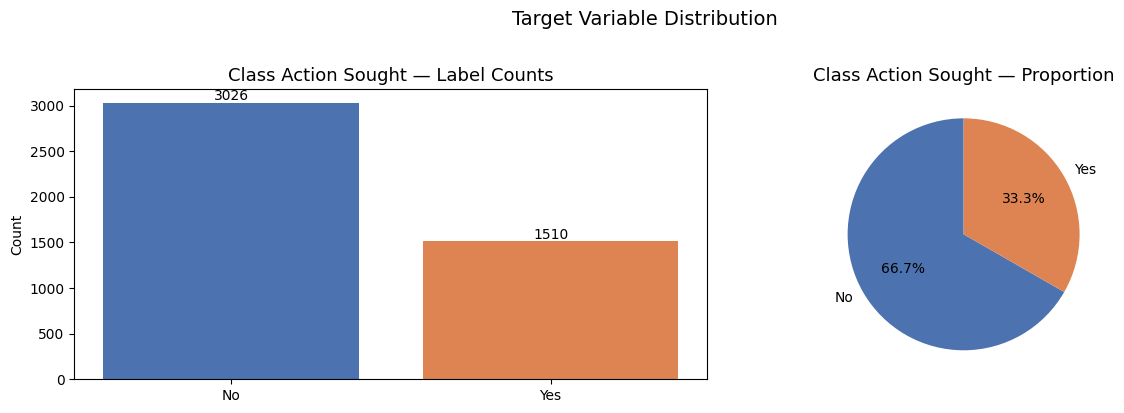

In [57]:
# Visualise label balance
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

counts = df_model['class_action_sought'].value_counts()
axes[0].bar(counts.index, counts.values, color=['#4C72B0', '#DD8452', '#55A868'])
axes[0].set_title('Class Action Sought — Label Counts', fontsize=13)
axes[0].set_ylabel('Count')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 30, str(v), ha='center', fontsize=10)

axes[1].pie(counts.values, labels=counts.index, autopct='%1.1f%%',
            colors=['#4C72B0', '#DD8452', '#55A868'], startangle=90)
axes[1].set_title('Class Action Sought — Proportion', fontsize=13)

plt.suptitle('Target Variable Distribution', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('fig_label_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

### 2.6 Train / Validation / Test Split Strategy

The dataset already provides official splits. We honour them to avoid data leakage:
- **Train** — model fitting
- **Validation** — hyperparameter selection
- **Test** — final, held-out evaluation (touched only once per model)

In [58]:
train_df  = df_model[df_model['split'] == 'train'].copy()
val_df    = df_model[df_model['split'] == 'validation'].copy()
test_df   = df_model[df_model['split'] == 'test'].copy()

print(f'Train:      {len(train_df):,} samples')
print(f'Validation: {len(val_df):,} samples')
print(f'Test:       {len(test_df):,} samples')

X_train, y_train = train_df['normalized_text'].tolist(), train_df['label'].tolist()
X_val,   y_val   = val_df['normalized_text'].tolist(),   val_df['label'].tolist()
X_test,  y_test  = test_df['normalized_text'].tolist(),  test_df['label'].tolist()

# Combine train+val for classical models (cross-validation handles selection)
X_trainval = X_train + X_val
y_trainval = y_train + y_val

Train:      3,175 samples
Validation: 453 samples
Test:       908 samples


In [59]:
print("Train labels:")
print(train_df['label'].value_counts())

print("\nValidation labels:")
print(val_df['label'].value_counts())

print("\nTest labels:")
print(test_df['label'].value_counts())

Train labels:
label
0    2109
1    1066
Name: count, dtype: int64

Validation labels:
label
0    298
1    155
Name: count, dtype: int64

Test labels:
label
0    619
1    289
Name: count, dtype: int64


## 3. Feature Engineering

We build two families of features:
1. **TF-IDF** — sparse bag-of-words representation weighted by term importance (fast, interpretable)
2. **Word2Vec embeddings** — dense document vectors from a Word2Vec model trained on the legal corpus

In [60]:
# TF-IDF
# We limit the vocabulary to 30,000 features and use unigrams + bigrams.
# max_df=0.95 drops terms that appear in >95% of documents (near-constant).
# min_df=5    drops terms that appear in fewer than 5 documents (very rare).
# sublinear_tf=True applies log(tf+1) to dampen the effect of high frequencies.

tfidf = TfidfVectorizer(
    max_features=30_000,
    ngram_range=(1, 2),
    max_df=0.95,
    min_df=5,
    sublinear_tf=True,
)
X_train_tfidf    = tfidf.fit_transform(X_train)      # fit ONLY on train
X_val_tfidf      = tfidf.transform(X_val)
X_test_tfidf     = tfidf.transform(X_test)
X_trainval_tfidf = tfidf.transform(X_trainval)

print(f'TF-IDF matrix shape (train): {X_train_tfidf.shape}')
print(f'Vocabulary size: {len(tfidf.vocabulary_):,}')

TF-IDF matrix shape (train): (3175, 30000)
Vocabulary size: 30,000


In [61]:
# Word2Vec
# Train a Word2Vec model on the training corpus (Skip-Gram, 100d).
# Using Skip-Gram (sg=1) is better for rare legal terms than CBOW.
# We then represent each document as the MEAN of its token vectors.

# Tokenise for Word2Vec (need list of token lists)
train_tokens = [text.split() for text in X_train]

w2v_model = Word2Vec(
    sentences=train_tokens,
    vector_size=100,
    window=5,
    min_count=3,
    sg=1,                # Skip-Gram
    workers=4,
    seed=RANDOM_STATE,
    epochs=10,
)
print(f'Word2Vec vocabulary size: {len(w2v_model.wv):,}')


def doc_to_vec(text, model, vector_size=100):
    """Return the mean Word2Vec vector for a document."""
    tokens = text.split()
    vecs = [model.wv[t] for t in tokens if t in model.wv]
    return np.mean(vecs, axis=0) if vecs else np.zeros(vector_size)


X_train_w2v    = np.array([doc_to_vec(t, w2v_model) for t in X_train])
X_val_w2v      = np.array([doc_to_vec(t, w2v_model) for t in X_val])
X_test_w2v     = np.array([doc_to_vec(t, w2v_model) for t in X_test])
X_trainval_w2v = np.array([doc_to_vec(t, w2v_model) for t in X_trainval])

print(f'Word2Vec document matrix shape (train): {X_train_w2v.shape}')

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl

Word2Vec vocabulary size: 230,774
Word2Vec document matrix shape (train): (3175, 100)


## 4. Model 1 — Naïve Bayes (Baseline)

In [62]:
# Fit Complement Naïve Bayes
nb_model = ComplementNB(alpha=0.1)   # alpha is the Laplace smoothing parameter
nb_model.fit(X_train_tfidf, y_train)

y_val_pred_nb  = nb_model.predict(X_val_tfidf)
y_test_pred_nb = nb_model.predict(X_test_tfidf)

print('=== Naïve Bayes — Validation Set ===')
print(classification_report(y_val, y_val_pred_nb, target_names=le.classes_))

print('=== Naïve Bayes — Test Set ===')
print(classification_report(y_test, y_test_pred_nb, target_names=le.classes_))

=== Naïve Bayes — Validation Set ===
              precision    recall  f1-score   support

          No       0.97      0.73      0.83       298
         Yes       0.65      0.96      0.77       155

    accuracy                           0.81       453
   macro avg       0.81      0.84      0.80       453
weighted avg       0.86      0.81      0.81       453

=== Naïve Bayes — Test Set ===
              precision    recall  f1-score   support

          No       0.98      0.73      0.84       619
         Yes       0.63      0.96      0.76       289

    accuracy                           0.81       908
   macro avg       0.80      0.85      0.80       908
weighted avg       0.87      0.81      0.81       908



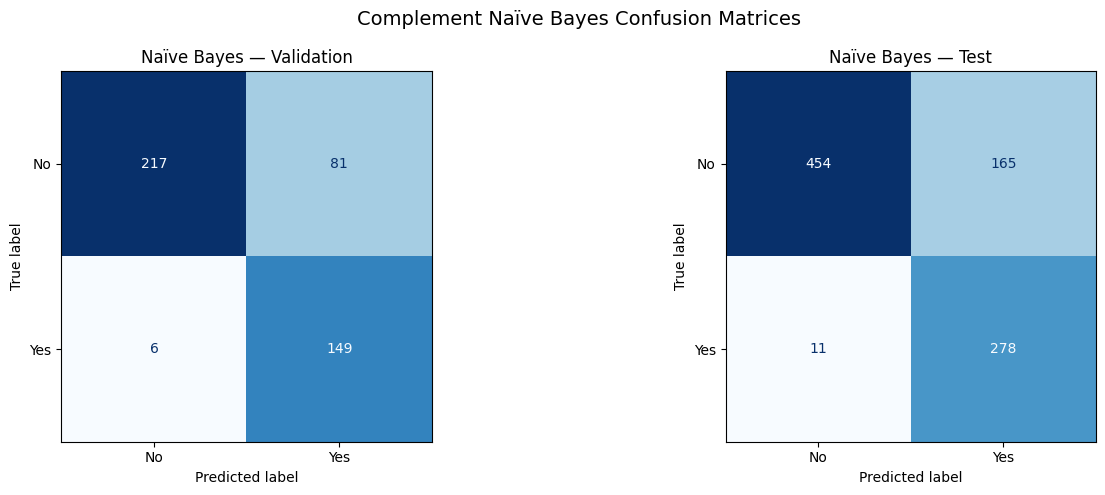

In [63]:
# Confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (y_true, y_pred, split) in zip(
    axes,
    [(y_val, y_val_pred_nb, 'Validation'), (y_test, y_test_pred_nb, 'Test')]
):
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=le.classes_)
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'Naïve Bayes — {split}', fontsize=12)

plt.suptitle('Complement Naïve Bayes Confusion Matrices', fontsize=14)
plt.tight_layout()
plt.savefig('fig_nb_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

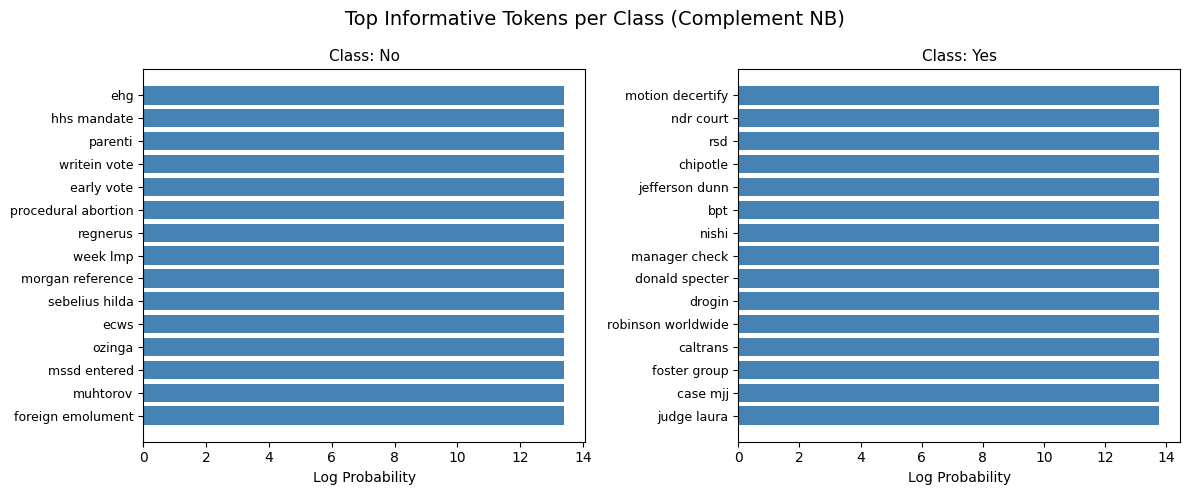

In [64]:
# Top informative tokens per class
# The log-probability feature weights in Naïve Bayes tell us which tokens are
# most diagnostic for each class — this is essentially semantic analysis via
# conditional probability.

feature_names = np.array(tfidf.get_feature_names_out())
n_top = 15

fig, axes = plt.subplots(1, n_classes, figsize=(6 * n_classes, 5))
if n_classes == 1:
    axes = [axes]

for cls_idx, (ax, cls_name) in enumerate(zip(axes, le.classes_)):
    # For CNB, feature_log_prob_ rows correspond to classes
    top_indices = nb_model.feature_log_prob_[cls_idx].argsort()[-n_top:][::-1]
    top_features = feature_names[top_indices]
    top_weights  = nb_model.feature_log_prob_[cls_idx][top_indices]

    ax.barh(range(n_top), top_weights[::-1], color='steelblue')
    ax.set_yticks(range(n_top))
    ax.set_yticklabels(top_features[::-1], fontsize=9)
    ax.set_title(f'Class: {cls_name}', fontsize=11)
    ax.set_xlabel('Log Probability')

plt.suptitle('Top Informative Tokens per Class (Complement NB)', fontsize=14)
plt.tight_layout()
plt.savefig('fig_nb_features.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Model 2 — Logistic Regression (TF-IDF)

Unlike Naïve Bayes, Logistic Regression does *not* assume feature independence — it learns a joint weight vector that balances correlated terms, making it more precise on legal vocabulary where related words (e.g. *class*, *action*, *certif*) co-occur systematically.

In [65]:
# Fit Logistic Regression on TF-IDF
lr_tfidf = LogisticRegression(
    C=1.0,                 # inverse regularisation strength
    max_iter=1000,
    solver='liblinear',
    multi_class='ovr',     # one-vs-rest for 3-class problem
    class_weight='balanced',  # up-weight minority classes
    random_state=RANDOM_STATE,
)
lr_tfidf.fit(X_train_tfidf, y_train)

y_val_pred_lr  = lr_tfidf.predict(X_val_tfidf)
y_test_pred_lr = lr_tfidf.predict(X_test_tfidf)

print('=== Logistic Regression (TF-IDF) — Validation Set ===')
print(classification_report(y_val, y_val_pred_lr, target_names=le.classes_))

labels = np.arange(len(le.classes_)) 

print('=== Logistic Regression (TF-IDF) — Test Set ===')
print(classification_report(
    y_test,
    y_test_pred_lr,
    labels=labels,
    target_names=le.classes_,
    zero_division=0
))

=== Logistic Regression (TF-IDF) — Validation Set ===
              precision    recall  f1-score   support

          No       0.96      0.94      0.95       298
         Yes       0.89      0.93      0.91       155

    accuracy                           0.94       453
   macro avg       0.93      0.94      0.93       453
weighted avg       0.94      0.94      0.94       453

=== Logistic Regression (TF-IDF) — Test Set ===
              precision    recall  f1-score   support

          No       0.97      0.98      0.97       619
         Yes       0.95      0.93      0.94       289

    accuracy                           0.96       908
   macro avg       0.96      0.96      0.96       908
weighted avg       0.96      0.96      0.96       908



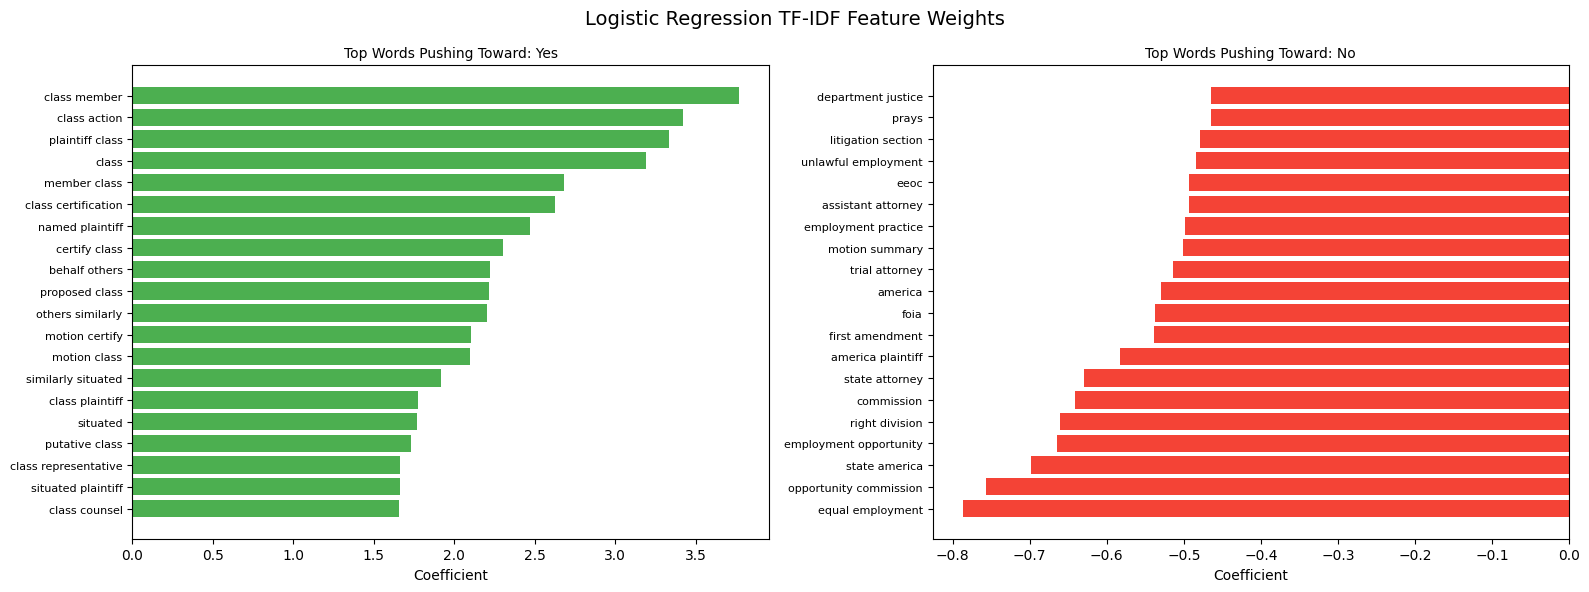

In [67]:
# Top positive and negative coefficients for binary Logistic Regression
# Positive coefficients push toward class 1; negative coefficients push toward class 0.

n_top = 20

coef = lr_tfidf.coef_[0]

class_0 = le.classes_[0]
class_1 = le.classes_[1]

top_pos = np.argsort(coef)[-n_top:][::-1]
top_neg = np.argsort(coef)[:n_top]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax_pos, ax_neg = axes

ax_pos.barh(range(n_top), coef[top_pos][::-1], color='#4CAF50')
ax_pos.set_yticks(range(n_top))
ax_pos.set_yticklabels(feature_names[top_pos][::-1], fontsize=8)
ax_pos.set_title(f'Top Words Pushing Toward: {class_1}', fontsize=10)
ax_pos.set_xlabel('Coefficient')

ax_neg.barh(range(n_top), coef[top_neg], color='#f44336')
ax_neg.set_yticks(range(n_top))
ax_neg.set_yticklabels(feature_names[top_neg], fontsize=8)
ax_neg.set_title(f'Top Words Pushing Toward: {class_0}', fontsize=10)
ax_neg.set_xlabel('Coefficient')

plt.suptitle('Logistic Regression TF-IDF Feature Weights', fontsize=14)
plt.tight_layout()
plt.savefig('fig_lr_tfidf_weights.png', dpi=150, bbox_inches='tight')
plt.show()

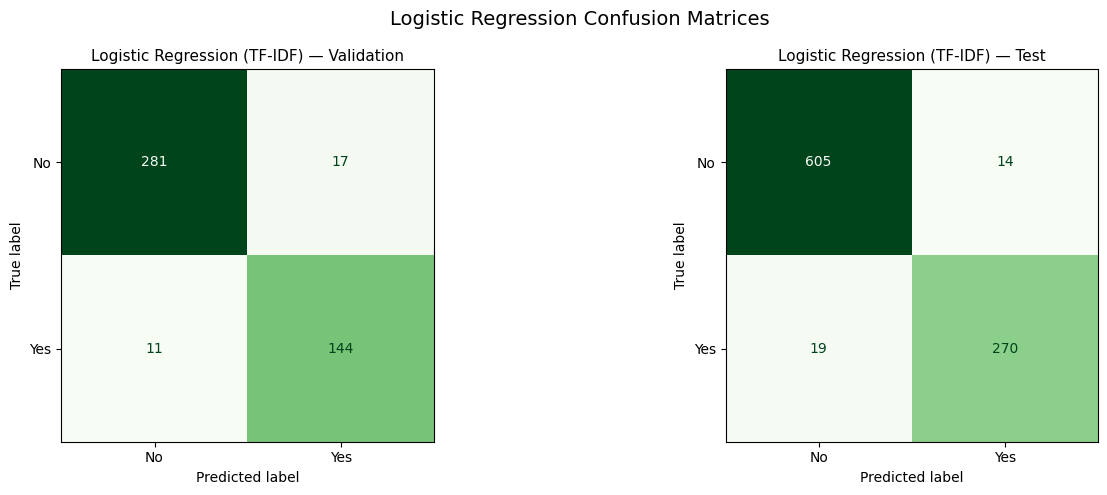

In [68]:
# Confusion matrices
labels = np.arange(len(le.classes_))

# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (y_true, y_pred, split) in zip(
    axes,
    [(y_val, y_val_pred_lr, 'Validation'), (y_test, y_test_pred_lr, 'Test')]
):
    cm = confusion_matrix(y_true, y_pred, labels=labels)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=le.classes_
    ).plot(ax=ax, colorbar=False, cmap='Greens')

    ax.set_title(f'Logistic Regression (TF-IDF) — {split}', fontsize=11)

plt.suptitle('Logistic Regression Confusion Matrices', fontsize=14)
plt.tight_layout()
plt.savefig('fig_lr_tfidf_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Model 3 — Logistic Regression (Word2Vec Embeddings)

Instead of sparse TF-IDF vectors, we feed the **dense Word2Vec document embeddings** (mean-pooled token vectors) into Logistic Regression. This tests whether semantic vector space provides additional signal beyond term frequency.

In [69]:
lr_w2v = LogisticRegression(
    C=1.0,
    max_iter=1000,
    solver='lbfgs',        
    multi_class='multinomial',
    class_weight='balanced',
    random_state=RANDOM_STATE,
)
lr_w2v.fit(X_train_w2v, y_train)

y_val_pred_lr_w2v  = lr_w2v.predict(X_val_w2v)
y_test_pred_lr_w2v = lr_w2v.predict(X_test_w2v)

print('=== Logistic Regression (Word2Vec) — Validation Set ===')
print(classification_report(y_val, y_val_pred_lr_w2v, target_names=le.classes_))

print('=== Logistic Regression (Word2Vec) — Test Set ===')
print(classification_report(y_test, y_test_pred_lr_w2v, target_names=le.classes_))

=== Logistic Regression (Word2Vec) — Validation Set ===
              precision    recall  f1-score   support

          No       0.95      0.87      0.90       298
         Yes       0.78      0.90      0.84       155

    accuracy                           0.88       453
   macro avg       0.86      0.88      0.87       453
weighted avg       0.89      0.88      0.88       453

=== Logistic Regression (Word2Vec) — Test Set ===
              precision    recall  f1-score   support

          No       0.96      0.86      0.90       619
         Yes       0.75      0.91      0.82       289

    accuracy                           0.88       908
   macro avg       0.85      0.89      0.86       908
weighted avg       0.89      0.88      0.88       908



## 7. Model 4 — BERT Embeddings + Logistic Regression

BERT produces *contextualised* word embeddings using a self-attention Transformer architecture. Unlike Word2Vec, BERT's representation of a word changes based on surrounding context which is critical for legal language where the same term can carry very different meanings.

In [70]:
import ipywidgets as widgets
widgets.IntSlider()

# Load BERT and extract [CLS] embeddings
from transformers import BertTokenizer, BertForSequenceClassification
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW

BERT_MODEL_NAME = 'bert-base-uncased'
MAX_LEN = 512
BATCH_SIZE = 8
EPOCHS = 3
LR = 2e-5

bert_tokenizer = BertTokenizer.from_pretrained(BERT_MODEL_NAME)


class LegalTextDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=512):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoded = self.tokenizer(
            self.texts[idx],
            max_length=self.max_len,
            truncation=True,
            padding='max_length',
            return_tensors='pt'
        )

        return {
            'input_ids': encoded['input_ids'].squeeze(0),
            'attention_mask': encoded['attention_mask'].squeeze(0),
            'labels': torch.tensor(self.labels[idx], dtype=torch.long)
        }


train_bert_dataset = LegalTextDataset(
    train_df['cleaned_text'].tolist(),
    y_train,
    bert_tokenizer,
    MAX_LEN
)

val_bert_dataset = LegalTextDataset(
    val_df['cleaned_text'].tolist(),
    y_val,
    bert_tokenizer,
    MAX_LEN
)

test_bert_dataset = LegalTextDataset(
    test_df['cleaned_text'].tolist(),
    y_test,
    bert_tokenizer,
    MAX_LEN
)

train_bert_loader = DataLoader(train_bert_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_bert_loader = DataLoader(val_bert_dataset, batch_size=BATCH_SIZE)
test_bert_loader = DataLoader(test_bert_dataset, batch_size=BATCH_SIZE)

bert_model = BertForSequenceClassification.from_pretrained(
    BERT_MODEL_NAME,
    num_labels=n_classes
).to(DEVICE)

optimizer = AdamW(bert_model.parameters(), lr=LR)

for epoch in range(EPOCHS):
    bert_model.train()
    total_loss = 0

    for batch in tqdm(train_bert_loader, desc=f'Fine-tuning BERT Epoch {epoch+1}/{EPOCHS}'):
        optimizer.zero_grad()

        input_ids = batch['input_ids'].to(DEVICE)
        attention_mask = batch['attention_mask'].to(DEVICE)
        labels_batch = batch['labels'].to(DEVICE)

        outputs = bert_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels_batch
        )

        loss = outputs.loss
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f'Epoch {epoch+1} loss: {total_loss / len(train_bert_loader):.4f}')

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Fine-tuning BERT Epoch 1/3:   0%|          | 0/397 [00:00<?, ?it/s]

Epoch 1 loss: 0.4201


Fine-tuning BERT Epoch 2/3:   0%|          | 0/397 [00:00<?, ?it/s]

Epoch 2 loss: 0.2450


Fine-tuning BERT Epoch 3/3:   0%|          | 0/397 [00:00<?, ?it/s]

Epoch 3 loss: 0.1973


In [71]:
def predict_bert(model, data_loader):
    model.eval()
    preds = []
    probs = []

    with torch.no_grad():
        for batch in tqdm(data_loader, desc='Evaluating BERT'):
            input_ids = batch['input_ids'].to(DEVICE)
            attention_mask = batch['attention_mask'].to(DEVICE)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            logits = outputs.logits
            batch_probs = torch.softmax(logits, dim=1)
            batch_preds = torch.argmax(batch_probs, dim=1)

            preds.extend(batch_preds.cpu().numpy())
            probs.extend(batch_probs.cpu().numpy())

    return np.array(preds), np.array(probs)


y_val_pred_bert, y_val_prob_bert = predict_bert(bert_model, val_bert_loader)
y_test_pred_bert, y_test_prob_bert = predict_bert(bert_model, test_bert_loader)

print('=== Fine-Tuned BERT — Validation Set ===')
print(classification_report(y_val, y_val_pred_bert, target_names=le.classes_))

labels = np.arange(len(le.classes_))

print('=== Fine-Tuned BERT — Test Set ===')
print(classification_report(
    y_test,
    y_test_pred_bert,
    labels=labels,
    target_names=le.classes_,
    zero_division=0
))






Evaluating BERT:   0%|          | 0/57 [00:00<?, ?it/s]

Evaluating BERT:   0%|          | 0/114 [00:00<?, ?it/s]

=== Fine-Tuned BERT — Validation Set ===
              precision    recall  f1-score   support

          No       0.93      0.92      0.93       298
         Yes       0.85      0.87      0.86       155

    accuracy                           0.90       453
   macro avg       0.89      0.90      0.89       453
weighted avg       0.90      0.90      0.90       453

=== Fine-Tuned BERT — Test Set ===
              precision    recall  f1-score   support

          No       0.93      0.92      0.92       619
         Yes       0.83      0.84      0.84       289

    accuracy                           0.90       908
   macro avg       0.88      0.88      0.88       908
weighted avg       0.90      0.90      0.90       908



Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


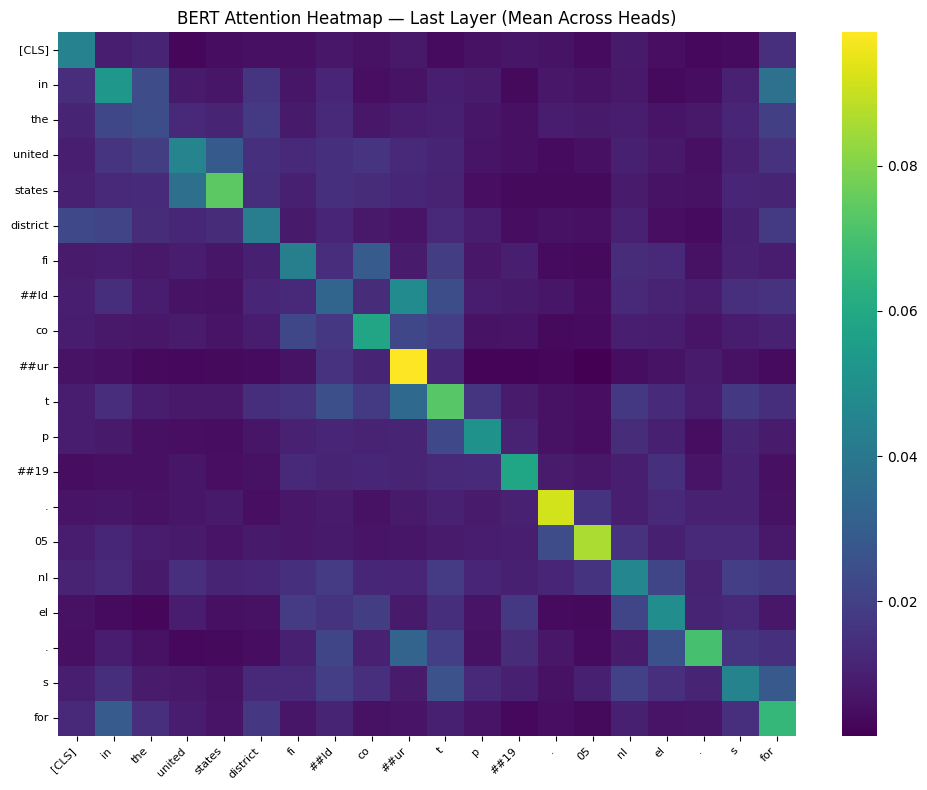

In [ ]:
# Attention pattern visualisation (single example)

sample_text = train_df['cleaned_text'].iloc[0][:300]   # first 300 chars

bert_model_with_attn = BertModel.from_pretrained(BERT_MODEL_NAME, output_attentions=True).to(DEVICE)
bert_model_with_attn.eval()

encoded_sample = bert_tokenizer(
    sample_text, max_length=64, truncation=True, padding='max_length',
    return_tensors='pt'
)
with torch.no_grad():
    outputs_sample = bert_model_with_attn(
        input_ids=encoded_sample['input_ids'].to(DEVICE),
        attention_mask=encoded_sample['attention_mask'].to(DEVICE),
    )

# Take the last layer's average attention across heads
last_layer_attn  = outputs_sample.attentions[-1].squeeze(0)   # (heads, seq, seq)
avg_attn         = last_layer_attn.mean(dim=0).cpu().numpy()  # (seq, seq)

tokens = bert_tokenizer.convert_ids_to_tokens(encoded_sample['input_ids'][0])
n_display = 20

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    avg_attn[:n_display, :n_display],
    xticklabels=tokens[:n_display],
    yticklabels=tokens[:n_display],
    cmap='viridis',
    ax=ax
)
ax.set_title('BERT Attention Heatmap — Last Layer (Mean Across Heads)', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.savefig('fig_bert_attention.png', dpi=150, bbox_inches='tight')
plt.show()

# Free memory
del bert_model_with_attn

## 8. Model 5 — LSTM Neural Network

Long Short-Term Memory (LSTM) networks can capture **sequential context** in text. Unlike bag-of-words models, an LSTM reads the token sequence left to right and optionally right to left, maintaining a hidden state that carries information across many time steps.

For legal documents, this matters as phrases like *"class action NOT sought"* require understanding word order. Our architecture:

```
Input tokens → Embedding (Word2Vec init) → BiLSTM → Global Max Pool → Dropout → Linear → Softmax
```

We initialise the embedding layer with our trained Word2Vec weights so the network starts with pre-learned legal semantics.

In [73]:
# Build vocabulary and pad sequences
from collections import Counter as _Counter

# Build vocabulary from training set
all_train_tokens = [text.split() for text in X_train]
vocab_counter = _Counter(tok for doc in all_train_tokens for tok in doc)
vocab = ['<PAD>', '<UNK>'] + [w for w, c in vocab_counter.items() if c >= 3]
word2idx = {w: i for i, w in enumerate(vocab)}

VOCAB_SIZE = len(vocab)
SEQ_LEN    = 512     # truncate / pad to 512 tokens
EMBED_DIM  = 100

print(f'Vocabulary size: {VOCAB_SIZE:,}')


def encode_and_pad(texts, word2idx, seq_len=SEQ_LEN):
    """Encode tokens to indices and pad/truncate to seq_len."""
    encoded = []
    for text in texts:
        tokens = text.split()[:seq_len]
        indices = [word2idx.get(t, 1) for t in tokens]  # 1 = <UNK>
        # Pad with 0 (<PAD>)
        padded = indices + [0] * (seq_len - len(indices))
        encoded.append(padded)
    return np.array(encoded, dtype=np.int64)


X_train_seq = encode_and_pad(X_train, word2idx)
X_val_seq   = encode_and_pad(X_val,   word2idx)
X_test_seq  = encode_and_pad(X_test,  word2idx)

print(f'Sequence matrix shape (train): {X_train_seq.shape}')

Vocabulary size: 230,776
Sequence matrix shape (train): (3175, 512)


In [74]:
# Build Word2Vec embedding matrix
# We initialise the LSTM's embedding layer with Word2Vec weights.
# This gives the network a head start with legal semantics.

embedding_matrix = np.zeros((VOCAB_SIZE, EMBED_DIM))
for word, idx in word2idx.items():
    if word in w2v_model.wv:
        embedding_matrix[idx] = w2v_model.wv[word]

print(f'Embedding matrix shape: {embedding_matrix.shape}')
coverage = sum(1 for w in vocab if w in w2v_model.wv) / VOCAB_SIZE
print(f'Vocabulary coverage in Word2Vec: {coverage:.1%}')

Embedding matrix shape: (230776, 100)
Vocabulary coverage in Word2Vec: 100.0%


In [75]:
# Define LSTM Model

class BiLSTMClassifier(nn.Module):
    """
    Bidirectional LSTM classifier with:
    - Pre-trained Word2Vec embeddings (optionally frozen)
    - 2-layer BiLSTM
    - Global max pooling over time steps
    - Dropout regularisation
    - Linear output layer
    """
    def __init__(self, vocab_size, embed_dim, hidden_dim, n_classes,
                 embedding_matrix=None, freeze_embeddings=False, dropout=0.4):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        if embedding_matrix is not None:
            self.embedding.weight.data.copy_(torch.from_numpy(embedding_matrix).float())
        if freeze_embeddings:
            self.embedding.weight.requires_grad = False

        self.lstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=2,
            batch_first=True,
            bidirectional=True,   # forward + backward context
            dropout=dropout if 2 > 1 else 0,
        )

        self.dropout = nn.Dropout(dropout)
        # BiLSTM doubles the hidden dim
        self.fc = nn.Linear(hidden_dim * 2, n_classes)

    def forward(self, x):
        emb = self.dropout(self.embedding(x))   # (batch, seq, embed)
        out, _ = self.lstm(emb)                  # (batch, seq, hidden*2)
        # Global max pooling across time steps
        pooled = out.max(dim=1).values           # (batch, hidden*2)
        return self.fc(self.dropout(pooled))     # (batch, n_classes)

In [76]:
# Training utilities

def make_dataloader(X, y, batch_size=32, shuffle=True):
    X_tensor = torch.LongTensor(X)
    y_tensor = torch.LongTensor(y)
    return DataLoader(
        TensorDataset(X_tensor, y_tensor),
        batch_size=batch_size,
        shuffle=shuffle
    )


def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
        optimizer.zero_grad()
        logits = model(X_batch)
        loss   = criterion(logits, y_batch)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)  # gradient clipping
        optimizer.step()
        total_loss += loss.item() * len(y_batch)
        correct    += (logits.argmax(1) == y_batch).sum().item()
        total      += len(y_batch)
    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    all_preds = []
    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
        logits = model(X_batch)
        loss   = criterion(logits, y_batch)
        total_loss += loss.item() * len(y_batch)
        preds   = logits.argmax(1)
        correct += (preds == y_batch).sum().item()
        total   += len(y_batch)
        all_preds.extend(preds.cpu().numpy())
    return total_loss / total, correct / total, all_preds


# Compute class weights for weighted cross-entropy (handles imbalance)
from sklearn.utils.class_weight import compute_class_weight
class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights_tensor = torch.FloatTensor(class_weights).to(DEVICE)
print(f'Class weights: {dict(zip(le.classes_, class_weights.round(3)))}')

Class weights: {'No': 0.753, 'Yes': 1.489}


In [77]:
# Instantiate and train the LSTM
HIDDEN_DIM  = 128
N_EPOCHS    = 10
LR          = 1e-3
BATCH_SIZE  = 32

train_loader = make_dataloader(X_train_seq, y_train, batch_size=BATCH_SIZE)
val_loader   = make_dataloader(X_val_seq,   y_val,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = make_dataloader(X_test_seq,  y_test,  batch_size=BATCH_SIZE, shuffle=False)

lstm_model = BiLSTMClassifier(
    vocab_size=VOCAB_SIZE,
    embed_dim=EMBED_DIM,
    hidden_dim=HIDDEN_DIM,
    n_classes=n_classes,
    embedding_matrix=embedding_matrix,
    freeze_embeddings=False,
    dropout=0.4,
).to(DEVICE)

criterion  = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer  = torch.optim.Adam(lstm_model.parameters(), lr=LR)
scheduler  = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=2, factor=0.5)

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_loss = float('inf')
best_state    = None

print(f'Training BiLSTM on {DEVICE}...')
for epoch in range(1, N_EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(lstm_model, train_loader, optimizer, criterion)
    vl_loss, vl_acc, _ = evaluate(lstm_model, val_loader, criterion)
    scheduler.step(vl_loss)

    history['train_loss'].append(tr_loss)
    history['val_loss'].append(vl_loss)
    history['train_acc'].append(tr_acc)
    history['val_acc'].append(vl_acc)

    if vl_loss < best_val_loss:
        best_val_loss = vl_loss
        best_state    = {k: v.cpu().clone() for k, v in lstm_model.state_dict().items()}

    print(f'Epoch {epoch:2d}/{N_EPOCHS} | '
          f'Train Loss: {tr_loss:.4f} Acc: {tr_acc:.3f} | '
          f'Val Loss: {vl_loss:.4f} Acc: {vl_acc:.3f}')

# Load best checkpoint
lstm_model.load_state_dict({k: v.to(DEVICE) for k, v in best_state.items()})
print('\nBest model loaded from checkpoint.')

Training BiLSTM on cpu...
Epoch  1/10 | Train Loss: 0.4728 Acc: 0.771 | Val Loss: 0.3469 Acc: 0.830
Epoch  2/10 | Train Loss: 0.2937 Acc: 0.889 | Val Loss: 0.3572 Acc: 0.885
Epoch  3/10 | Train Loss: 0.2525 Acc: 0.909 | Val Loss: 0.2834 Acc: 0.885
Epoch  4/10 | Train Loss: 0.2104 Acc: 0.923 | Val Loss: 0.3016 Acc: 0.898
Epoch  5/10 | Train Loss: 0.1750 Acc: 0.943 | Val Loss: 0.3016 Acc: 0.898
Epoch  6/10 | Train Loss: 0.1340 Acc: 0.955 | Val Loss: 0.4284 Acc: 0.890
Epoch  7/10 | Train Loss: 0.0923 Acc: 0.967 | Val Loss: 0.3553 Acc: 0.890
Epoch  8/10 | Train Loss: 0.0801 Acc: 0.974 | Val Loss: 0.4406 Acc: 0.887
Epoch  9/10 | Train Loss: 0.0679 Acc: 0.980 | Val Loss: 0.4412 Acc: 0.894
Epoch 10/10 | Train Loss: 0.0608 Acc: 0.983 | Val Loss: 0.4473 Acc: 0.890

Best model loaded from checkpoint.


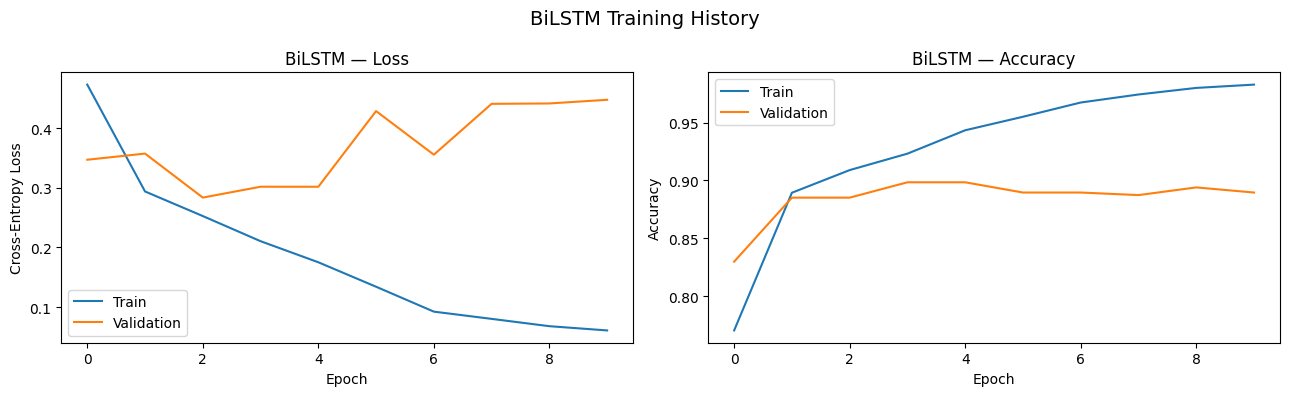

In [78]:
# Plot training history
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history['train_loss'], label='Train')
axes[0].plot(history['val_loss'],   label='Validation')
axes[0].set_title('BiLSTM — Loss', fontsize=12)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].legend()

axes[1].plot(history['train_acc'], label='Train')
axes[1].plot(history['val_acc'],   label='Validation')
axes[1].set_title('BiLSTM — Accuracy', fontsize=12)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.suptitle('BiLSTM Training History', fontsize=14)
plt.tight_layout()
plt.savefig('fig_lstm_history.png', dpi=150, bbox_inches='tight')
plt.show()

In [79]:
# LSTM test-set evaluation
_, _, y_val_pred_lstm  = evaluate(lstm_model, val_loader,  criterion)
_, _, y_test_pred_lstm = evaluate(lstm_model, test_loader, criterion)

print('=== BiLSTM — Validation Set ===')
print(classification_report(y_val, y_val_pred_lstm, target_names=le.classes_))

labels = np.arange(len(le.classes_)) 

print('=== BiLSTM — Test Set ===')
print(classification_report(
    y_test,
    y_test_pred_lstm,
    labels=labels,
    target_names=le.classes_,
    zero_division=0
))

=== BiLSTM — Validation Set ===
              precision    recall  f1-score   support

          No       0.96      0.86      0.91       298
         Yes       0.78      0.93      0.85       155

    accuracy                           0.89       453
   macro avg       0.87      0.90      0.88       453
weighted avg       0.90      0.89      0.89       453

=== BiLSTM — Test Set ===
              precision    recall  f1-score   support

          No       0.95      0.88      0.91       619
         Yes       0.77      0.90      0.83       289

    accuracy                           0.88       908
   macro avg       0.86      0.89      0.87       908
weighted avg       0.89      0.88      0.89       908



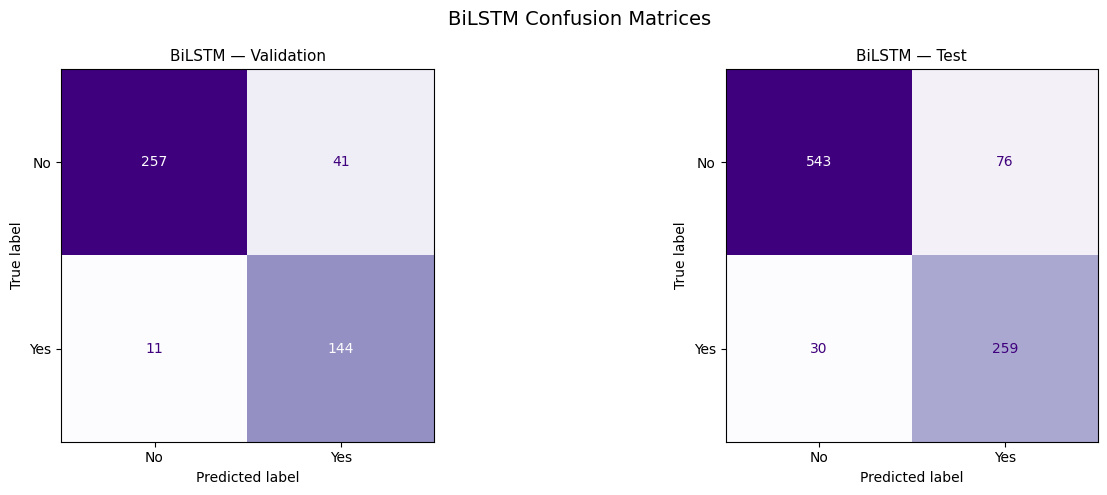

In [80]:
# Confusion matrix
labels = np.arange(len(le.classes_))

# Confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (y_true, y_pred, split) in zip(
    axes,
    [(y_val, y_val_pred_lstm, 'Validation'), (y_test, y_test_pred_lstm, 'Test')]
):
    cm = confusion_matrix(y_true, y_pred, labels=labels)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=le.classes_
    ).plot(ax=ax, colorbar=False, cmap='Purples')

    ax.set_title(f'BiLSTM — {split}', fontsize=11)

plt.suptitle('BiLSTM Confusion Matrices', fontsize=14)
plt.tight_layout()
plt.savefig('fig_lstm_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Full Evaluation & Model Comparison

We compare all four models on the held-out **test set** using:
- **Accuracy** — overall correctness
- **Macro F1** — unweighted average F1 across classes (penalises ignoring minority classes)
- **Weighted F1** — F1 weighted by class support
- **ROC-AUC (OvR)** — discriminative power, one-vs-rest

In [81]:
# Collect all predictions and probabilities
results = {}

labels = np.arange(len(le.classes_))
n_classes = len(le.classes_)

def safe_roc_auc(y_true, y_prob):
    present_classes = np.unique(y_true)

    # ROC-AUC is undefined if only one class is present
    if len(present_classes) < 2:
        return "N/A"

    # If only two classes are present, compute binary ROC-AUC
    if len(present_classes) == 2:
        positive_class = present_classes[1]
        return roc_auc_score(
            y_true == positive_class,
            y_prob[:, positive_class]
        )

    # If all classes are present, compute multiclass OvR ROC-AUC
    return roc_auc_score(
        y_true,
        y_prob,
        labels=present_classes,
        multi_class='ovr',
        average='macro'
    )

models_info = {
    'Complement NB (TF-IDF)':         (y_test_pred_nb,     nb_model.predict_proba(X_test_tfidf)),
    'Logistic Reg (TF-IDF)':          (y_test_pred_lr,     lr_tfidf.predict_proba(X_test_tfidf)),
    'Logistic Reg (Word2Vec)':        (y_test_pred_lr_w2v, lr_w2v.predict_proba(X_test_w2v)),
    'Fine-Tuned BERT':                (y_test_pred_bert,   y_test_prob_bert),
    'BiLSTM (Word2Vec Init)':         (y_test_pred_lstm,   None),
}

for name, (y_pred, y_prob) in models_info.items():
    acc = accuracy_score(y_test, y_pred)

    macro_f1 = f1_score(
        y_test,
        y_pred,
        labels=labels,
        average='macro',
        zero_division=0
    )

    wtd_f1 = f1_score(
        y_test,
        y_pred,
        labels=labels,
        average='weighted',
        zero_division=0
    )

    if y_prob is not None:
        auc = safe_roc_auc(y_test, y_prob)
    else:
        auc = "N/A"

    results[name] = {
        'Accuracy': acc,
        'Macro F1': macro_f1,
        'Weighted F1': wtd_f1,
        'ROC-AUC': auc
    }

results_df = pd.DataFrame(results).T

# Round numeric columns only
for col in ['Accuracy', 'Macro F1', 'Weighted F1']:
    results_df[col] = results_df[col].round(4)

results_df['ROC-AUC'] = results_df['ROC-AUC'].apply(
    lambda x: round(x, 4) if isinstance(x, float) else x
)

print('=== Model Comparison — Test Set ===')
display(results_df.sort_values('Macro F1', ascending=False))

=== Model Comparison — Test Set ===


,Accuracy,Macro F1,Weighted F1,ROC-AUC
Logistic Reg (TF-IDF),0.963656,0.95793,0.963571,0.9882
Fine-Tuned BERT,0.896476,0.881156,0.896664,0.9505
BiLSTM (Word2Vec Init),0.88326,0.870601,0.88531,N/A
Logistic Reg (Word2Vec),0.876652,0.864881,0.879375,0.9633
Complement NB (TF-IDF),0.806167,0.798601,0.812788,0.9542


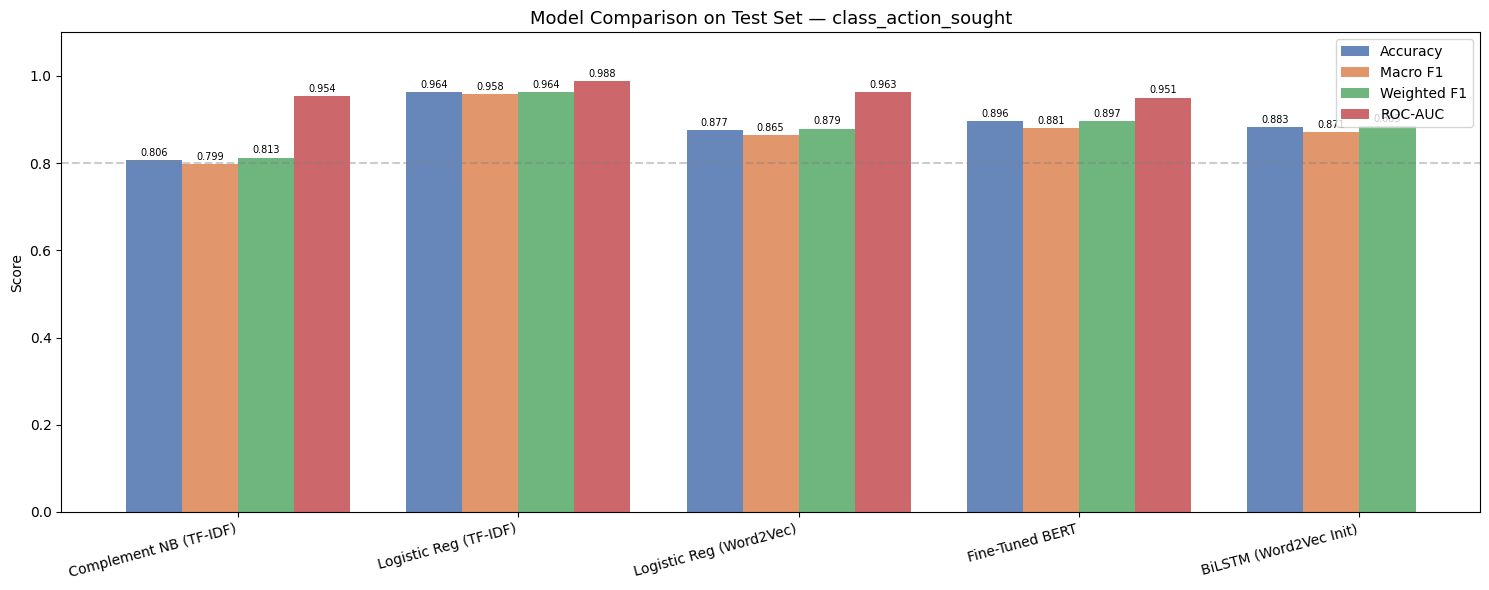

In [82]:
# Bar chart comparison
metrics_to_plot = ['Accuracy', 'Macro F1', 'Weighted F1', 'ROC-AUC']

plot_df = results_df.copy()

# Convert N/A values to NaN for plotting
for metric in metrics_to_plot:
    plot_df[metric] = pd.to_numeric(plot_df[metric], errors='coerce')

x = np.arange(len(plot_df))
width = 0.2
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

fig, ax = plt.subplots(figsize=(15, 6))

for i, (metric, color) in enumerate(zip(metrics_to_plot, colors)):
    vals = plot_df[metric].values

    bars = ax.bar(
        x + i * width,
        vals,
        width,
        label=metric,
        color=color,
        alpha=0.85
    )

    for bar, val in zip(bars, vals):
        if not np.isnan(val):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.005,
                f'{val:.3f}',
                ha='center',
                va='bottom',
                fontsize=7
            )

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(plot_df.index, rotation=15, ha='right', fontsize=10)
ax.set_ylabel('Score')
ax.set_ylim(0, 1.1)
ax.set_title('Model Comparison on Test Set — class_action_sought', fontsize=13)

ax.axhline(y=0.8, color='gray', linestyle='--', alpha=0.4)
ax.legend(loc='upper right')

plt.tight_layout()
plt.savefig('fig_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

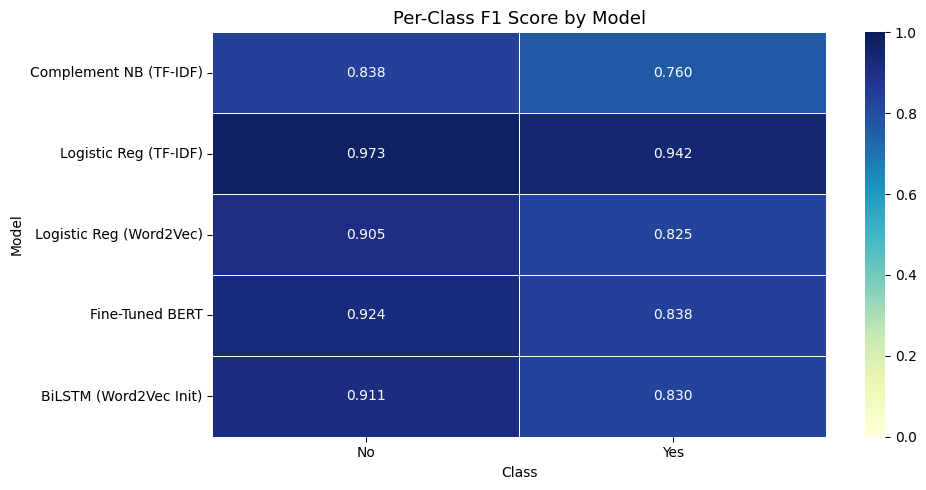

In [83]:
# Per-class performance heatmap
# Show F1 per class for each model to expose where each model struggles.

labels = np.arange(len(le.classes_))

per_class_f1 = {}

for name, (y_pred, _) in models_info.items():
    report = classification_report(
        y_test,
        y_pred,
        labels=labels,
        target_names=le.classes_,
        output_dict=True,
        zero_division=0
    )

    per_class_f1[name] = {
        cls: report[cls]['f1-score']
        for cls in le.classes_
    }

heatmap_df = pd.DataFrame(per_class_f1).T

fig, ax = plt.subplots(figsize=(10, 5))

sns.heatmap(
    heatmap_df,
    annot=True,
    fmt='.3f',
    cmap='YlGnBu',
    linewidths=0.5,
    vmin=0,
    vmax=1,
    ax=ax
)

ax.set_title('Per-Class F1 Score by Model', fontsize=13)
ax.set_xlabel('Class')
ax.set_ylabel('Model')

plt.tight_layout()
plt.savefig('fig_per_class_f1.png', dpi=150, bbox_inches='tight')
plt.show()

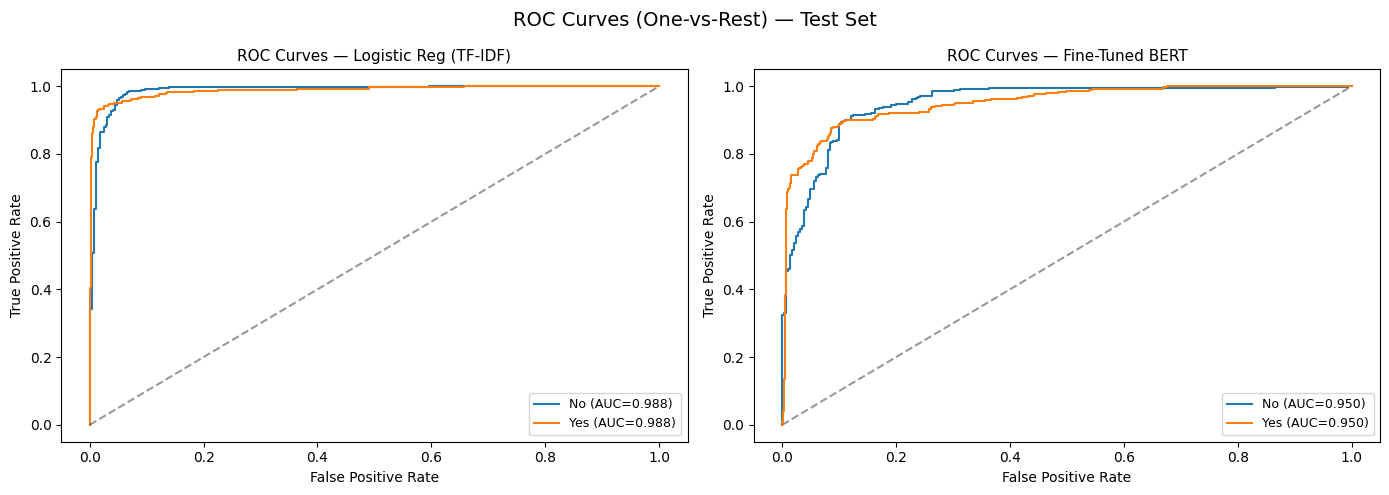

In [85]:
# ROC Curves (one-vs-rest, best two models)
labels = np.arange(len(le.classes_))
n_classes = len(le.classes_)

y_test_bin = label_binarize(y_test, classes=labels)

if n_classes == 2 and y_test_bin.shape[1] == 1:
    y_test_bin = np.hstack([1 - y_test_bin, y_test_bin])

roc_models = {
    'Logistic Reg (TF-IDF)': lr_tfidf.predict_proba(X_test_tfidf),
    'Fine-Tuned BERT':       y_test_prob_bert,
}

colors = cycle(['darkorange', 'cornflowerblue', 'green', 'purple'])

fig, axes = plt.subplots(1, len(roc_models), figsize=(14, 5))

if len(roc_models) == 1:
    axes = [axes]

for ax, (model_name, y_score) in zip(axes, roc_models.items()):
    for cls_i, cls_name in enumerate(le.classes_):

        y_true_binary = y_test_bin[:, cls_i]

        # Skip class if y_true has only one class: all 0s or all 1s
        if len(np.unique(y_true_binary)) < 2:
            print(f"Skipping ROC for '{cls_name}' because it is not present as both positive and negative in y_test.")
            continue

        fpr, tpr, _ = roc_curve(y_true_binary, y_score[:, cls_i])
        auc_score = roc_auc_score(y_true_binary, y_score[:, cls_i])

        ax.plot(fpr, tpr, label=f'{cls_name} (AUC={auc_score:.3f})')

    ax.plot([0, 1], [0, 1], 'k--', alpha=0.4)
    ax.set_title(f'ROC Curves — {model_name}', fontsize=11)
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.legend(fontsize=9)

plt.suptitle('ROC Curves (One-vs-Rest) — Test Set', fontsize=14)
plt.tight_layout()
plt.savefig('fig_roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Error Analysis

Understanding *which* cases the best model gets wrong is often more instructive than aggregate metrics.

In [ ]:
# Identify misclassified examples
best_model_name = results_df['Macro F1'].idxmax()
print(f'Best model: {best_model_name}')

# Map model name to predictions array
pred_map = dict(zip(models_info.keys(), [v[0] for v in models_info.values()]))
y_best_pred = pred_map[best_model_name]

test_df_copy = test_df.copy().reset_index(drop=True)
test_df_copy['y_true'] = y_test
test_df_copy['y_pred'] = y_best_pred
test_df_copy['correct'] = test_df_copy['y_true'] == test_df_copy['y_pred']

errors = test_df_copy[~test_df_copy['correct']].copy()
print(f'\nTotal misclassified: {len(errors)} / {len(test_df_copy)} ({100*len(errors)/len(test_df_copy):.1f}%)')

# Error breakdown by true vs. predicted label
error_breakdown = errors.groupby(['y_true', 'y_pred']).size().reset_index(name='count')
error_breakdown['true_label'] = le.inverse_transform(error_breakdown['y_true'])
error_breakdown['pred_label'] = le.inverse_transform(error_breakdown['y_pred'])
print('\nError confusion breakdown:')
display(error_breakdown[['true_label', 'pred_label', 'count']])

Best model: Logistic Reg (TF-IDF)

Total misclassified: 33 / 908 (3.6%)

Error confusion breakdown:


,true_label,pred_label,count
0,No,Yes,14
1,Yes,No,19


In [90]:
# Show misclassified examples with context
print('--- Sample misclassified cases ---\n')
for _, row in errors.head(5).iterrows():
    true_lbl = le.inverse_transform([row['y_true']])[0]
    pred_lbl = le.inverse_transform([row['y_pred']])[0]
    snippet  = row['cleaned_text'][:400].replace('\n', ' ')
    print(f'Case: {row["case_name"]}')
    print(f'True: {true_lbl}  →  Predicted: {pred_lbl}')
    print(f'Snippet: {snippet}...')
    print('-' * 80)

--- Sample misclassified cases ---

Case: Mitchell v. City of Montgomery
True: No  →  Predicted: Yes
Snippet: RECEiVED IN THE UNITED STATES DIscTcquR FOR THE MIDDLE DISTRICTLO ALAAMA 1 SHARNALLE MITCHELL, LORENZO BROWN, DEB -RA P. HCETT. CLV US u 1 STCid 3 ALA flCTr'T I Li Li L i 4 COURTNEY TUBBS, TITO WILLIAMS, Plaintiffs, V. THE CITY OF MONTGOMERY, Case No. _________ Defendant. COMPLAINT Introduction The Plaintiffs in this case are each impowrished people who were jailed by the City of Montgomery becaus...
--------------------------------------------------------------------------------
Case: Cleveland v. City of Montgomery & Watts v. City of Montgomery
True: No  →  Predicted: Yes
Snippet: Case: 2:13-cv-732 As of: 01/18/2019 10:59 AM CST 1 of 8 CLOSED,JOINT_ASSIGN,LEAD U.S. District Court Alabama Middle District (Montgomery) CIVIL DOCKET FOR CASE #: 2:13−cv−00732−MHT−TFM Cleveland v. City of Montgomery et al (LEAD)(JOINT ASSIGN) Assigned to: Honorable Judge Myron H. Thompson Referred 

## 11. Save Models for Interactive Tool

We save the best scikit-learn pipeline and the LSTM state dict so the interactive tool can load them without retraining.

In [91]:
import pickle
import torch

# Save models and preprocessing objects
artifacts = {
    'label_encoder': le,
    'tfidf_vectorizer': tfidf,
    'lr_tfidf_model': lr_tfidf,
    'w2v_model': w2v_model,
    'lr_w2v_model': lr_w2v,
    'word2idx': word2idx,
}

# Save BERT classifier if available
artifacts['lr_bert_model'] = lr_bert

with open('class_action_models.pkl', 'wb') as f:
    pickle.dump(artifacts, f)

# Save LSTM state dict separately
torch.save(lstm_model.state_dict(), 'lstm_class_action.pt')

print('Models saved:')
print('  class_action_models.pkl  — sklearn models, vectorizers, label encoder')
print('  lstm_class_action.pt     — BiLSTM weights')

Models saved:
  class_action_models.pkl  — sklearn models, vectorizers, label encoder
  lstm_class_action.pt     — BiLSTM weights


## 12. Inference Helper — Predict on New Text

This is the function interactive tool will call.

In [94]:
def predict_class_action(raw_text: str, model_choice: str = 'tfidf_lr') -> dict:
    """
    Predict whether class action was sought for a raw legal case text.

    Parameters
    ----------
    raw_text : str
        The raw (uncleaned) text of a legal case.
    model_choice : str
        One of 'tfidf_lr', 'w2v_lr', 'bert'  (default: 'tfidf_lr')

    Returns
    -------
    dict with 'prediction' (str label) and 'probabilities' (dict)
    """
    import re, string
    from nltk.tokenize import word_tokenize
    from nltk.corpus import stopwords
    from nltk.stem import WordNetLemmatizer

    stop_words  = set(stopwords.words('english'))
    lemmatizer  = WordNetLemmatizer()
    re_url      = re.compile(r'https?://\S+|www\.\S+')
    re_cite     = re.compile(r'\b\d+\s+(?:U\.S\.|F\.3d|F\.2d|F\.Supp\.?\d*|S\.Ct\.|L\.Ed\.2d)\s+\d+\b')
    re_fn       = re.compile(r'\[\d+\]')
    re_space    = re.compile(r'\s+')

    # Light cleaning (matches teammate's clean_text)
    cleaned = raw_text.replace('\x0c', ' ')
    cleaned = re_url.sub('', cleaned)
    cleaned = re_cite.sub('', cleaned)
    cleaned = re_fn.sub('', cleaned)
    cleaned = re_space.sub(' ', cleaned).strip()

    # Full normalisation (matches teammate's normalize_text)
    normalized = cleaned.lower()
    normalized = normalized.translate(str.maketrans('', '', string.punctuation))
    tokens = word_tokenize(normalized)
    tokens = [
        lemmatizer.lemmatize(t)
        for t in tokens
        if t.isalpha() and t not in stop_words and len(t) > 2
    ]
    normalized = ' '.join(tokens)

    if model_choice == 'tfidf_lr':
        vec   = tfidf.transform([normalized])
        probs = lr_tfidf.predict_proba(vec)[0]
    elif model_choice == 'w2v_lr':
        vec   = doc_to_vec(normalized, w2v_model).reshape(1, -1)
        probs = lr_w2v.predict_proba(vec)[0]
    elif model_choice == 'bert':

        bert_model.eval()

        encoded = bert_tokenizer(
            [cleaned],
            padding=True,
            truncation=True,
            max_length=512,
            return_tensors='pt'
        )

        encoded = {k: v.to(DEVICE) for k, v in encoded.items()}

        with torch.no_grad():
            outputs = bert_model(**encoded)

        # Case 1: Fine-tuned classifier model
        if hasattr(outputs, "logits"):
            logits = outputs.logits
            probs = torch.softmax(logits, dim=1).cpu().numpy()[0]

        # Case 2: Base BertModel embedding model
        elif hasattr(outputs, "last_hidden_state"):
            emb = outputs.last_hidden_state[:, 0, :].cpu().numpy()
            probs = lr_bert.predict_proba(emb)[0]

        else:
            raise ValueError("BERT output does not contain logits or last_hidden_state.")
    else:
        raise ValueError(f'Unknown model_choice: {model_choice}')

    pred_idx = int(np.argmax(probs))
    return {
        'prediction':    le.inverse_transform([pred_idx])[0],
        'probabilities': dict(zip(le.classes_, probs.round(4).tolist())),
    }


# ── Quick smoke test ──────────────────────────────────────────────────────────
sample = """This case involves a large group of employees at a manufacturing facility
who allege systematic racial discrimination in hiring and promotions.
Plaintiffs seek certification of a class action on behalf of all similarly situated workers."""

for choice in ['tfidf_lr', 'bert', 'w2v_lr']:
    result = predict_class_action(sample, model_choice=choice)
    print(f"[{choice}] Prediction: {result['prediction']}")
    print(f"         Probabilities: {result['probabilities']}")
    print()

[tfidf_lr] Prediction: Yes
         Probabilities: {'No': 0.2602, 'Yes': 0.7398}

[bert] Prediction: Yes
         Probabilities: {'No': 0.016699999570846558, 'Yes': 0.983299970626831}

[w2v_lr] Prediction: Yes
         Probabilities: {'No': 0.0, 'Yes': 1.0}



## Summary of Findings

| Model | Feature Representation | Key Strengths | Key Limitations |
|---------|---------|---------|---------|
| **Complement Naïve Bayes** | TF-IDF | Extremely fast, computationally efficient, works well with sparse text features | Assumes feature independence and struggles with complex relationships between legal terms |
| **Logistic Regression** | TF-IDF | Best overall performance (96.4% accuracy, 0.988 ROC-AUC); highly interpretable; effective on high-dimensional legal vocabulary | Linear decision boundary; cannot explicitly model word order or long-range context |
| **Logistic Regression** | Word2Vec | Captures semantic similarity and synonymy through dense embeddings; smaller feature space | Mean-pooled embeddings lose word order and document structure information |
| **Fine-Tuned BERT** | Contextual Transformer Embeddings | Captures contextual meaning, negation, and semantic relationships; strong generalization performance | Limited to the first 512 tokens of each document; computationally expensive; underperformed TF-IDF on this task |
| **BiLSTM** | Word2Vec (Initialized) | Models sequential context and word order; less computationally expensive than BERT | Fixed vocabulary, potential overfitting, and weaker performance than simpler TF-IDF approaches |

### Key Finding: Traditional NLP Outperformed Deep Learning

Contrary to expectations, the strongest model was **Logistic Regression with TF-IDF features**, achieving **96.4% test accuracy, 95.8% macro F1, 96.4% weighted F1, and 0.988 ROC-AUC**. This model outperformed all neural approaches, including Fine-Tuned BERT and BiLSTM.

These results suggest that the class-action prediction task is driven primarily by highly discriminative legal terminology rather than subtle contextual relationships. Legal phrases such as *class certification*, *similarly situated plaintiffs*, *representative action*, and related procedural language provide strong lexical signals that are captured effectively by TF-IDF features. Because TF-IDF utilizes the entire document, it can leverage information appearing anywhere within the case text.

### Why BERT Did Not Outperform TF-IDF

Although BERT is generally considered state-of-the-art for many text classification tasks, several characteristics of this dataset likely limited its performance.

First, Multi-LexSum legal cases are often extremely long, while BERT processes only the first 512 tokens of each document. Important evidence regarding class-action status may appear later in the case text and therefore remains unavailable to the model.

Second, the prediction target appears strongly associated with specific legal terminology. In such settings, sparse term-frequency representations can outperform more complex contextual embeddings because the presence of key legal phrases is often more informative than deeper semantic understanding.

Finally, after removing records labeled *Unknown*, only 4,536 cases remained available for modeling. While sufficient for traditional machine learning methods, this dataset size is relatively small for fully leveraging transformer-based architectures. Consequently, the additional complexity of BERT did not translate into improved predictive performance.

### Error Analysis

The best-performing model misclassified only **33 of 908 test cases (3.6%)**. The error breakdown consisted of **14 false positives** and **19 false negatives**, indicating relatively balanced mistakes across classes.

Inspection of misclassified examples revealed that many false positives contained language commonly associated with class-action litigation, including civil-rights claims, discrimination allegations, government defendants, and large groups of plaintiffs. Cases such as *Mitchell v. City of Montgomery* and *Antoninetti v. Chipotle Mexican Grill* contain terminology that closely resembles genuine class-action filings even though class certification was not actually sought. This suggests substantial vocabulary overlap between the two classes and highlights one of the primary challenges of legal text classification.

### Class Imbalance Handling

After removing three records labeled *Unknown*, the final dataset contained:

- **No:** 3,026 cases (66.7%)
- **Yes:** 1,510 cases (33.3%)

Because the classes were moderately imbalanced, balancing strategies were incorporated into model training. Logistic Regression models used `class_weight='balanced'`, while the BiLSTM used weighted cross-entropy loss based on class frequencies. These approaches prevented models from favoring the majority *No* class and improved performance on the minority *Yes* class.

The resulting class-specific metrics demonstrate that the best-performing models maintained strong performance across both categories rather than simply maximizing overall accuracy. For the TF-IDF Logistic Regression model, F1-scores exceeded 0.94 for both classes, indicating robust and balanced classification performance.